# Zoo analysis: are the mistakes bears from the same zoo?

The 13 bears live in **6 zoos** (listed in the dataset's `animal_db.csv`): five zoos with 2 bears and Hannover with 3. Bears in the same zoo share an enclosure, lighting and cameras.

**Question:** when the baseline gets a bear wrong, does it pick a bear from the **same zoo** more often than chance? And when it gets the bear right, is the runner-up (the most similar *wrong* bear) a zoo-mate?

**Chance level:** if the wrong bear were a random pick among the other 12 bears, it would be a zoo-mate with probability 1/12 = 8% (a bear in a 2-bear zoo) or 2/12 = 17% (a Hannover bear), about **10-11% on average**.

**Words used below**
- **mistake:** a validation video matched to a training video of the wrong bear (24 of 215).
- **runner-up bear:** the most similar bear that is *not* the true bear. For a mistake, it is the predicted bear.
- **zoo-mate:** a different bear living in the same zoo.

Validation videos are the queries, training videos the gallery (the baseline: 20 frames averaged per video, cosine nearest neighbour). The test split is never used.

## 0. Imports and setup

In [1]:
import os
import sys
from pathlib import Path

# Run from the repo folder (one level up from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

import heatmaps
import zoo_analysis

## 1. The bears and their zoos

This table comes with the dataset (`animal_db.csv`, written by the dataset authors).

In [2]:
bears = pd.read_csv("data/PolarBearVidID/animal_db.csv")
bears

,id,name,type,sex,birth,zoo,tracklets
0,0,Vera,PolarBear,female,2002,Tiergarten Nürnberg,123
1,1,Nanuq,PolarBear,male,2007,Tiergarten Nürnberg,105
2,2,Tonja,PolarBear,female,2009,Tierpark Berlin,108
3,3,Hertha,PolarBear,female,2018,Tierpark Berlin,118
4,4,Nora,PolarBear,female,2013,Tiergarten Schönbrunn,104
5,5,Finja,PolarBear,female,2019,Tiergarten Schönbrunn,107
6,6,Larissa,PolarBear,female,1990,Tierpark Neumünster,107
7,7,Vitus,PolarBear,male,2000,Tierpark Neumünster,104
8,8,Lloyd,PolarBear,male,2000,Zoo Karlsruhe,120
9,9,Charlotte,PolarBear,female,2014,Zoo Karlsruhe,112


**Check:** the file's IDs match our bear folders (id 0 = folder `000`). Its `tracklets` column (videos per bear) must equal the number of videos we have for each bear.

In [3]:
frames, _ = heatmaps.load_frames()
videos_per_bear = frames.drop_duplicates("sequence").groupby("identity").size()
(bears["tracklets"].values == videos_per_bear.values).all()

np.True_

In [4]:
zoos = zoo_analysis.load_zoos()
zoos.value_counts()

zoo
Zoo Hannover             3
Tiergarten Nürnberg      2
Tierpark Berlin          2
Tiergarten Schönbrunn    2
Tierpark Neumünster      2
Zoo Karlsruhe            2
Name: count, dtype: int64

## 2. Rerun the baseline on every validation video

The same matching as `core_objective.py` (88.84%, 191 of 215).

In [5]:
results, _ = heatmaps.match_query_videos()
res = zoo_analysis.add_zoo_columns(results, zoos)
res["correct"].agg(["sum", "count", "mean"])

sum      191.000000
count    215.000000
mean       0.888372
Name: correct, dtype: float64

## 3. Accuracy per zoo

In [6]:
table = zoo_analysis.zoo_table(res, zoos)
table[["bears", "videos", "correct", "mistakes", "accuracy_%"]]

,bears,videos,correct,mistakes,accuracy_%
zoo,,,,,
Tiergarten Nürnberg,"000, 001",34,30,4,88.2
Tierpark Berlin,"002, 003",34,27,7,79.4
Tiergarten Schönbrunn,"004, 005",32,29,3,90.6
Tierpark Neumünster,"006, 007",32,32,0,100.0
Zoo Karlsruhe,"008, 009",35,32,3,91.4
Zoo Hannover,"010, 011, 012",48,41,7,85.4
All zoos,all 13,215,191,24,88.8


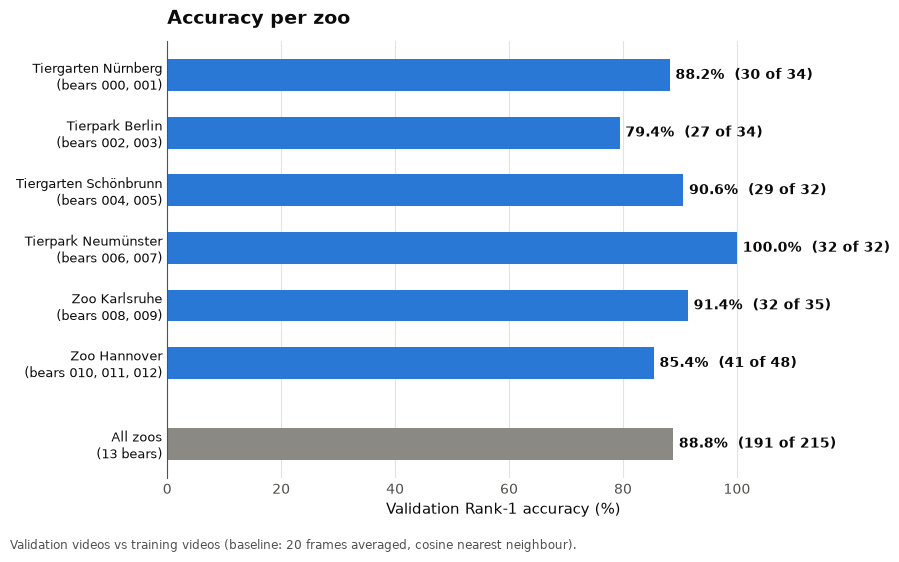

In [7]:
fig, path = zoo_analysis.plot_zoo_accuracy(table)
plt.show()

Accuracy per bear (each zoo's bears together):

In [8]:
zoo_analysis.bear_accuracy(res)

videos  correct  accuracy_%
zoo                   identity                             
Tiergarten Nürnberg   000           18       16        88.9
                      001           16       14        87.5
Tierpark Berlin       002           16       11        68.8
                      003           18       16        88.9
Tiergarten Schönbrunn 004           16       15        93.8
                      005           16       14        87.5
Tierpark Neumünster   006           16       16       100.0
                      007           16       16       100.0
Zoo Karlsruhe         008           18       17        94.4
                      009           17       15        88.2
Zoo Hannover          010           18       14        77.8
                      011           15       14        93.3
                      012           15       13        86.7

## 4. Where do each zoo's mistakes go?

- `mistakes_to_same_zoo`: mistakes where the predicted bear lives in the same zoo.
- `mistakes_to_other_zoo`: mistakes where it lives in a different zoo.
- `runner_up_same_zoo`: videos (correct or not) whose most similar wrong bear is a zoo-mate.

In [9]:
table[["bears", "mistakes", "mistakes_to_same_zoo", "mistakes_to_other_zoo", "runner_up_same_zoo"]]

,bears,mistakes,mistakes_to_same_zoo,mistakes_to_other_zoo,runner_up_same_zoo
zoo,,,,,
Tiergarten Nürnberg,"000, 001",4,3,1,23
Tierpark Berlin,"002, 003",7,6,1,21
Tiergarten Schönbrunn,"004, 005",3,0,3,12
Tierpark Neumünster,"006, 007",0,0,0,27
Zoo Karlsruhe,"008, 009",3,1,2,15
Zoo Hannover,"010, 011, 012",7,1,6,21
All zoos,all 13,24,11,13,119


## 5. All 24 mistakes

In [10]:
mistakes = res.loc[~res["correct"], ["sequence", "identity", "zoo", "predicted", "predicted_zoo",
                                     "predicted_zoo_mate", "margin"]]
mistakes.sort_values(["predicted_zoo_mate", "zoo"], ascending=[False, True]).round(3)

,sequence,identity,zoo,predicted,predicted_zoo,predicted_zoo_mate,margin
2,000C01T061,000,Tiergarten Nürnberg,001,Tiergarten Nürnberg,True,-0.004
13,000C03T064,000,Tiergarten Nürnberg,001,Tiergarten Nürnberg,True,-0.132
27,001C01T077,001,Tiergarten Nürnberg,000,Tiergarten Nürnberg,True,-0.029
36,002C01T038,002,Tierpark Berlin,003,Tierpark Berlin,True,-0.052
38,002C01T044,002,Tierpark Berlin,003,Tierpark Berlin,True,-0.042
43,002C01T101,002,Tierpark Berlin,003,Tierpark Berlin,True,-0.053
44,002C02T006,002,Tierpark Berlin,003,Tierpark Berlin,True,-0.000
47,002C02T074,002,Tierpark Berlin,003,Tierpark Berlin,True,-0.013
50,003C01T001,003,Tierpark Berlin,002,Tierpark Berlin,True,-0.057
199,011C03T101,011,Zoo Hannover,012,Zoo Hannover,True,-0.039


Which zoo-mate pairs get mixed up:

In [11]:
mistakes[mistakes["predicted_zoo_mate"]].groupby(["identity", "predicted"]).size().rename("mistakes")

identity  predicted
000       001          2
001       000          1
002       003          5
003       002          1
009       008          1
011       012          1
Name: mistakes, dtype: int64

## 6. Observed vs chance

`expected_by_chance` adds up each video's chance (1/12 or 2/12), so it is the count we would see if the model picked the wrong bear at random.

In [12]:
summary = zoo_analysis.observed_vs_chance(res)
summary.round(1)

,which bear,videos,zoo_mate,observed_%,expected_by_chance,chance_%
0,Mistakes: the predicted bear,24,11,45.8,2.6,10.8
1,Correct videos: the runner-up bear,191,108,56.5,19.3,10.1
2,All videos: the runner-up bear,215,119,55.3,21.9,10.2


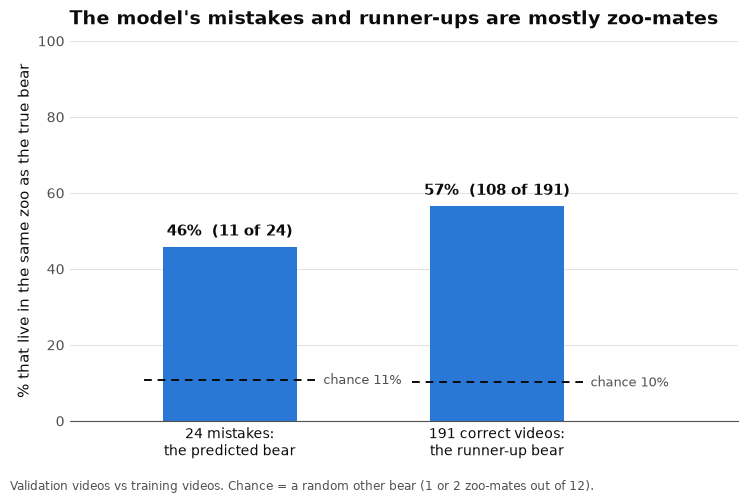

In [13]:
fig, path = zoo_analysis.plot_zoo_mate_share(summary)
plt.show()

## 7. Who is mistaken for whom?

Rows are the true bear, columns the other bear. Each orange square is one zoo, so **numbers inside the squares are zoo-mates**. If the model ignored zoos, the numbers would be spread evenly over the whole matrix.

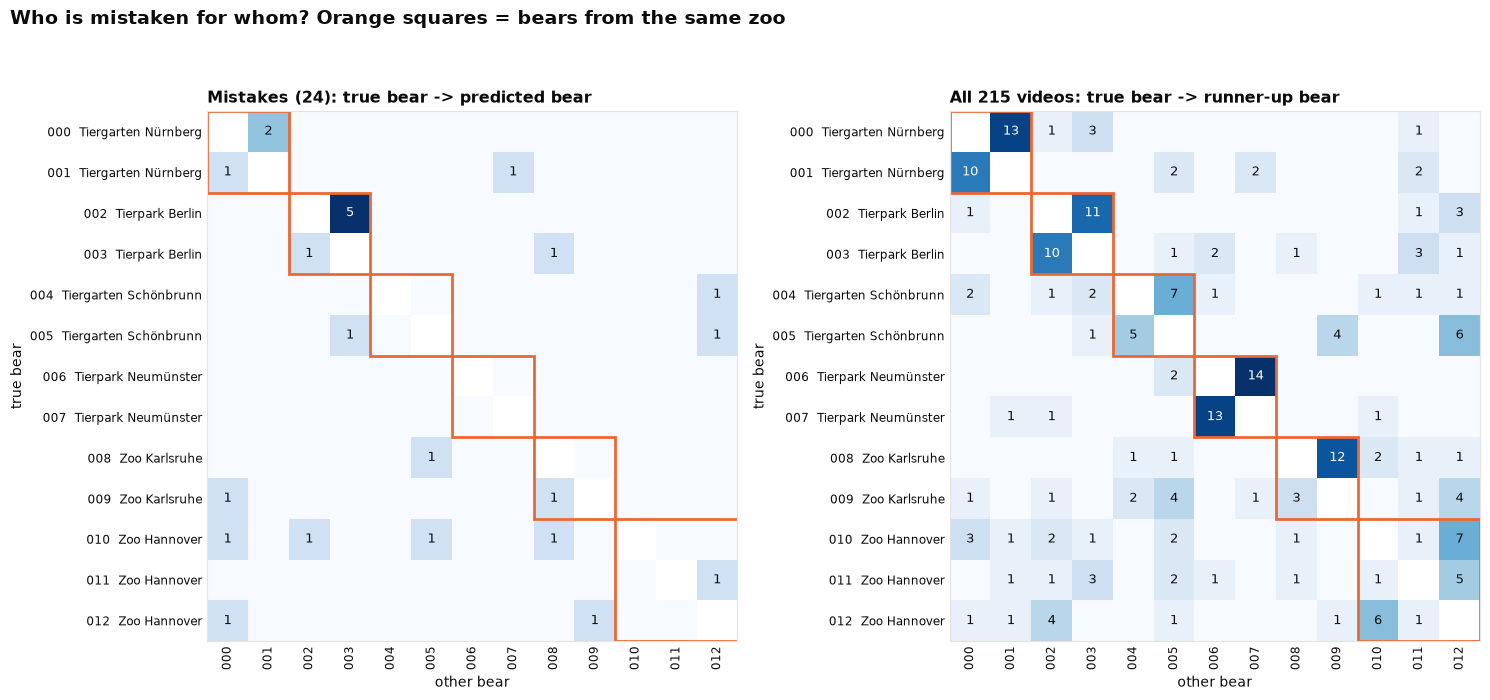

In [14]:
fig, path = zoo_analysis.plot_zoo_confusion(res, zoos)
plt.show()

## 8. What this does and does not show

- **It shows** that the model's idea of "similar" is grouped by zoo: both its mistakes and its runner-ups are zoo-mates far more often than chance.
- **It does not show why.** Zoo-mates share an enclosure, lighting and cameras, but they may also look alike (some may be related). The bear-vs-background test (`notebooks/background_test.ipynb`) separates the two: if zoo-mate mistakes stay high when only the bear is visible, the bears look alike; if they drop, the enclosure was causing them.